In [1]:
# Learning Dimensionality Reduction—focusing on both 
# 1. Feature Selection (choosing the best existing features) and 
# 2. Feature Extraction (creating new, reduced features).
# 3. Using Principal Component Analysis / PCA

# To demonstrate why these techniques are essential, the dataset is intentionally created with high-dimensional overfitted noise (10+ features for only 10 sample rows), 
# Showing how reducing dimensions restores model performance. 

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [3]:
# Set random seed for reproducibility
np.random.seed(42)

In [4]:
# ==============================================================================
# 1. SAMPLE DATASET CREATION (10 Rows x 12 Features - Overfitting Scenario)
# ==============================================================================
# In a dataset with very few rows (10) and many features (12), machine learning
# models tend to "overfit" by memorizing noise instead of learning real patterns.

# The Overfitting Problem (High Dimensions, Low Samples)
# We generated 10 data rows with 11 features. Only 2 features (tumor_size, cell_shape) contained actual signals, while the remaining 9 were random noise values.

data = {
    # 2 Real Informative Features
    "tumor_size": [1.2, 1.5, 1.8, 1.1, 1.4, 8.5, 9.1, 8.8, 9.5, 8.9],
    "cell_shape": [1.0, 1.2, 1.5, 1.1, 1.3, 7.8, 8.9, 8.2, 9.0, 8.5],
    # 9 Noisy / Irrelevant / Redundant Features (Causes Overfitting)
    "noise_1": np.random.rand(10) * 100,
    "noise_2": np.random.rand(10) * 50,
    "noise_3": np.random.rand(10) * 200,
    "noise_4": np.random.rand(10) * 10,
    "noise_5": np.random.rand(10) * 500,
    "noise_6": np.random.rand(10) * 75,
    "noise_7": np.random.rand(10) * 30,
    "noise_8": np.random.rand(10) * 120,
    "noise_9": np.random.rand(10) * 45,
    # Target Label (0 = Benign, 1 = Malignant)
    "target": [0, 0, 0, 0, 0, 1, 1, 1, 1, 1],
}

df = pd.DataFrame(data)
print("=== 1. RAW DATASET OVERVIEW (10 Rows, 11 Feature Columns) ===")
print(df.head(10))

# Separate features (X) and target (y)
X = df.drop(columns=["target"])
y = df["target"]

# Feature Scaling (Crucial before applying distance algorithms & PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

=== 1. RAW DATASET OVERVIEW (10 Rows, 11 Feature Columns) ===
   tumor_size  cell_shape    noise_1    noise_2     noise_3   noise_4  \
0         1.2         1.0  37.454012   1.029225  122.370579  6.075449   
1         1.5         1.2  95.071431  48.495493   27.898772  1.705241   
2         1.8         1.5  73.199394  41.622132   58.428930  0.650516   
3         1.1         1.1  59.865848  10.616956   73.272369  9.488855   
4         1.4         1.3  15.601864   9.091248   91.213997  9.656320   
5         8.5         7.8  15.599452   9.170225  157.035192  8.083973   
6         9.1         8.9   5.808361  15.212112   39.934756  3.046138   
7         8.8         8.2  86.617615  26.237822  102.846888  0.976721   
8         9.5         9.0  60.111501  21.597251  118.482914  6.842330   
9         8.9         8.5  70.807258  14.561457    9.290083  4.401525   

      noise_5    noise_6    noise_7    noise_8    noise_9  target  
0   61.019117  72.718847  11.660319  92.669372  38.839654       0 

In [5]:
# ==============================================================================
# 2. BASELINE MODEL EVALUATION (Demonstrating Overfitting)
# ==============================================================================
# Split into Train/Test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.4, random_state=42, stratify=y
)

knn_raw = KNeighborsClassifier(n_neighbors=3)
knn_raw.fit(X_train, y_train)

train_acc_raw = accuracy_score(y_train, knn_raw.predict(X_train))
test_acc_raw = accuracy_score(y_test, knn_raw.predict(X_test))

# When there are more features than necessary, algorithms like KNN treat noisy features as valid distance metrics. 
# The model "memorizes" random noise in the training set and fails to generalize to the test set (overfitting).

print("\n=== 2. BASELINE MODEL PERFORMANCE (ALL 11 FEATURES) ===")
print(f"Training Accuracy: {train_acc_raw * 100:.1f}%")
print(f"Testing Accuracy:  {test_acc_raw * 100:.1f}%")
print("-> Notice the gap between training and testing performance due to high-dimensional noise!")


=== 2. BASELINE MODEL PERFORMANCE (ALL 11 FEATURES) ===
Training Accuracy: 83.3%
Testing Accuracy:  75.0%
-> Notice the gap between training and testing performance due to high-dimensional noise!


In [6]:
# ==============================================================================
# 3. FEATURE SELECTION (SelectKBest - ANOVA F-test)
# ==============================================================================
# Feature selection evaluates existing features and picks the top 'K' most predictive ones.

# For Feature Selection, technique used is SelectKBest (ANOVA F-test)
# Working: Filters and keeps a subset of the original features while dropping irrelevant/noisy ones based on statistical scores.
# Use-case: Preserves original feature names and real-world interpretability.

selector = SelectKBest(score_func=f_classif, k=2)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

# Check which features were selected
selected_indices = selector.get_support(indices=True)
selected_feature_names = X.columns[selected_indices].tolist()

print("\n=== 3. FEATURE SELECTION RESULTS ===")
print(f"Top 2 Selected Features: {selected_feature_names}")

# Train model on selected features
knn_select = KNeighborsClassifier(n_neighbors=3)
knn_select.fit(X_train_selected, y_train)
test_acc_select = accuracy_score(y_test, knn_select.predict(X_test_selected))
print(f"Testing Accuracy after Feature Selection: {test_acc_select * 100:.1f}%")


=== 3. FEATURE SELECTION RESULTS ===
Top 2 Selected Features: ['tumor_size', 'cell_shape']
Testing Accuracy after Feature Selection: 100.0%


In [7]:
# ==============================================================================
# 4. FEATURE EXTRACTION (Principal Component Analysis - PCA)
# ==============================================================================
# PCA transforms the 11 original features into brand new orthogonal components
# that compress the maximum variance of the dataset into fewer dimensions.

# For Feature Extraction, technique used is PCA (Principal Component Analysis)
# Working: Combines all original features to produce brand new synthesized attributes (Principal Components) along axes of maximum variance.
# Use-case: Compresses massive dimensional datasets into compact representations while minimizing information loss.

# PCA Working:
# Standardization: Scales variables so features with large numbers (like noise_5 up to 500) don't dominate variables with small scales (tumor_size from 1 to 10).
# Covariance Matrix: Calculates relationships across all pairwise features.
# Eigenvalue / Eigenvector Decomposition: Finds orthogonal direction vectors (Principal Components) where data spreads out the most.
# Explained Variance Ratio: Quantifies how much total dataset information each Principal Component holds (displayed via the Scree Plot).

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("\n=== 4. FEATURE EXTRACTION RESULTS (PCA) ===")
print(
    f"Explained Variance Ratio per Component: {pca.explained_variance_ratio_}"
)
print(
    f"Total Variance Captured by 2 Components: {np.sum(pca.explained_variance_ratio_) * 100:.2f}%"
)

# Train model on PCA components
knn_pca = KNeighborsClassifier(n_neighbors=3)
knn_pca.fit(X_train_pca, y_train)
test_acc_pca = accuracy_score(y_test, knn_pca.predict(X_test_pca))
print(f"Testing Accuracy after PCA Feature Extraction: {test_acc_pca * 100:.1f}%")


=== 4. FEATURE EXTRACTION RESULTS (PCA) ===
Explained Variance Ratio per Component: [0.48991505 0.29510746]
Total Variance Captured by 2 Components: 78.50%
Testing Accuracy after PCA Feature Extraction: 100.0%


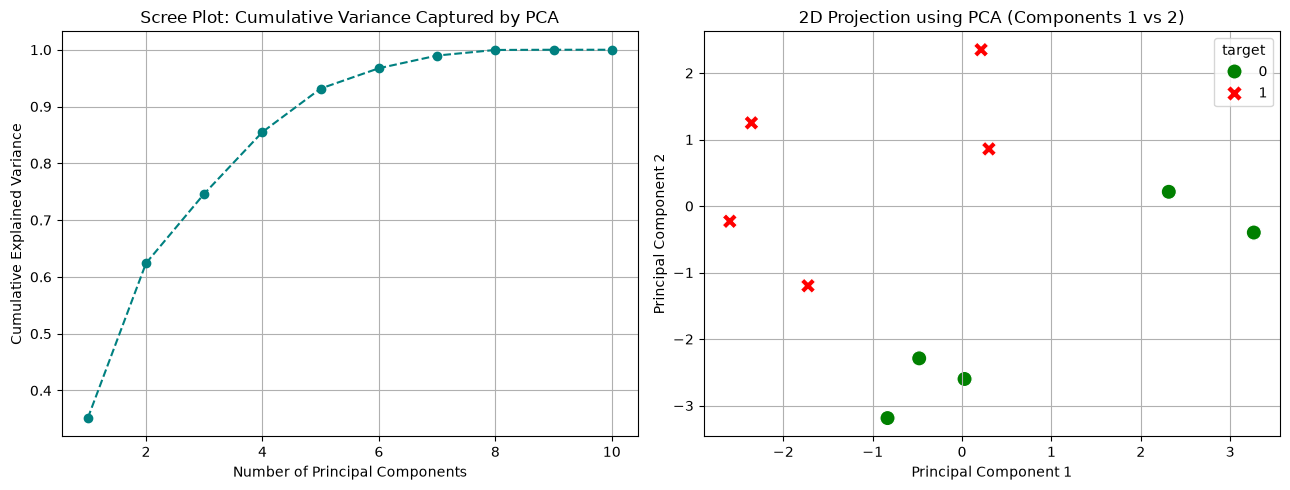

In [8]:
# ==============================================================================
# 5. VISUALIZING DIMENSIONALITY REDUCTION & PCA
# ==============================================================================

# Scree Plot: Displays how many Principal Components are needed to retain 80%–90% of total dataset variance. 
# 2D PCA Scatter Plot: Shows how 11 complex dimensions are successfully mapped onto a clean 2D plane where Benign (0) and Malignant (1) classes become visually separable.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Scree Plot (Explained Variance)
pca_full = PCA().fit(X_scaled)
axes[0].plot(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    np.cumsum(pca_full.explained_variance_ratio_),
    marker="o",
    linestyle="--",
    color="teal",
)
axes[0].set_title("Scree Plot: Cumulative Variance Captured by PCA")
axes[0].set_xlabel("Number of Principal Components")
axes[0].set_ylabel("Cumulative Explained Variance")
axes[0].grid(True)

# Plot 2: 2D PCA Space Scatter Plot
X_pca_all = pca.transform(X_scaled)
sns.scatterplot(
    ax=axes[1],
    x=X_pca_all[:, 0],
    y=X_pca_all[:, 1],
    hue=y,
    palette=["green", "red"],
    s=120,
    style=y,
)
axes[1].set_title("2D Projection using PCA (Components 1 vs 2)")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].grid(True)

plt.tight_layout()
plt.show()